# Pricing & Profitability Optimization

## Project: Retail Pricing, Demand & Profitability Decision Model

### Objective
To evaluate alternative pricing and discount strategies and understand their potential impact on estimated revenue, profit margins, and profitability.

### Business Questions
1. How do different discount levels affect estimated profitability?
2. Which discount strategy works best for each product category?
3. How can demand estimates support pricing decisions?
4. Where is the balance between demand growth and profit margin?
5. Which pricing scenarios offer the strongest estimated financial outcomes?

### Analysis Approach
This notebook will combine historical retail data, demand predictions, and explicitly documented hypothetical unit-cost assumptions to evaluate alternative pricing scenarios.

### Expected Outcome
A scenario-based pricing and profitability analysis that identifies potentially attractive pricing strategies while acknowledging the limitations of the available data.

### Important Note
The dataset does not contain verified product costs. Profitability calculations will therefore use illustrative cost assumptions and must not be interpreted as actual business profits.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original retail dataset
df = pd.read_csv("../Data/Raw/retail_demand.csv")

# Load demand predictions
predictions = pd.read_csv(
    "../Reports/final_demand_predictions.csv"
)

print("Retail dataset shape:", df.shape)
print("Demand predictions shape:", predictions.shape)

display(df.head())
display(predictions.head())

Retail dataset shape: (76000, 16)
Demand predictions shape: (15200, 4)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


,Date,Actual_Demand,Predicted_Demand,Prediction_Error
0,2023-09-01,182,169.03,12.97
1,2023-09-01,102,123.85,-21.85
2,2023-09-01,150,119.26,30.74
3,2023-09-01,117,139.77,-22.77
4,2023-09-01,134,150.61,-16.61


In [2]:
# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Sort data chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Recreate the chronological 80/20 split
split_date = df["Date"].unique()[
    int(len(df["Date"].unique()) * 0.80)
]

test_df = df[df["Date"] >= split_date].copy()

# Verify alignment
print("Test dataset shape:", test_df.shape)

print(
    "Dates match:",
    np.array_equal(
        test_df["Date"].values,
        pd.to_datetime(predictions["Date"]).values
    )
)

print(
    "Actual demand matches:",
    np.array_equal(
        test_df["Demand"].values,
        predictions["Actual_Demand"].values
    )
)

Test dataset shape: (15200, 16)
Dates match: True
Actual demand matches: True


In [3]:
# Create a working copy of the test dataset
pricing_df = test_df.copy()

# Attach predicted demand
pricing_df["Predicted_Demand"] = (
    predictions["Predicted_Demand"].values
)

print("Predicted demand attached successfully!")
print("Dataset shape:", pricing_df.shape)

display(
    pricing_df[
        [
            "Date",
            "Category",
            "Price",
            "Discount",
            "Demand",
            "Units Sold",
            "Predicted_Demand"
        ]
    ].head(10)
)

Predicted demand attached successfully!
Dataset shape: (15200, 17)


,Date,Category,Price,Discount,Demand,Units Sold,Predicted_Demand
60800,2023-09-01,Groceries,36.89,25,182,166,169.03
60801,2023-09-01,Groceries,27.56,10,102,121,123.85
60802,2023-09-01,Furniture,125.19,0,150,99,119.26
60803,2023-09-01,Groceries,19.67,10,117,83,139.77
60804,2023-09-01,Groceries,25.97,15,134,157,150.61
60805,2023-09-01,Clothing,62.63,10,145,94,106.86
60806,2023-09-01,Electronics,107.36,5,89,54,91.99
60807,2023-09-01,Clothing,71.71,5,106,107,112.60
60808,2023-09-01,Clothing,88.64,25,102,77,128.14
60809,2023-09-01,Groceries,67.65,5,176,186,174.95


In [4]:
pricing_summary = pricing_df[
    ["Price", "Discount", "Competitor Pricing", "Predicted_Demand"]
].describe().round(2)

display(pricing_summary)

,Price,Discount,Competitor Pricing,Predicted_Demand
count,15200.00,15200.00,15200.00,15200.00
mean,67.08,9.07,68.85,100.90
std,39.24,7.51,40.80,34.30
min,5.83,0.00,5.54,15.07
25%,31.38,5.00,31.88,80.75
50%,63.64,10.00,64.96,100.47
75%,94.76,10.00,97.25,122.64
max,209.90,25.00,240.36,265.85


In [5]:
category_pricing = pricing_df.groupby("Category").agg(
    Average_Price=("Price", "mean"),
    Average_Competitor_Price=("Competitor Pricing", "mean"),
    Average_Discount=("Discount", "mean"),
    Average_Predicted_Demand=("Predicted_Demand", "mean"),
    Records=("Price", "count")
)

display(
    category_pricing.round(2).sort_values(
        "Average_Price",
        ascending=False
    )
)

,Average_Price,Average_Competitor_Price,Average_Discount,Average_Predicted_Demand,Records
Category,,,,,
Furniture,120.93,124.03,9.03,72.38,2736
Electronics,82.62,84.89,9.02,96.67,1824
Clothing,71.84,73.74,9.02,113.36,2432
Groceries,50.55,51.92,9.09,114.18,6080
Toys,26.35,26.94,9.18,89.02,2128


In [6]:
category_pricing["Price_Difference"] = (
    category_pricing["Average_Price"]
    - category_pricing["Average_Competitor_Price"]
)

category_pricing["Price_Difference_%"] = (
    category_pricing["Price_Difference"]
    / category_pricing["Average_Competitor_Price"]
) * 100

display(
    category_pricing[
        [
            "Average_Price",
            "Average_Competitor_Price",
            "Price_Difference",
            "Price_Difference_%"
        ]
    ].round(2)
)

,Average_Price,Average_Competitor_Price,Price_Difference,Price_Difference_%
Category,,,,
Clothing,71.84,73.74,-1.91,-2.58
Electronics,82.62,84.89,-2.27,-2.67
Furniture,120.93,124.03,-3.10,-2.50
Groceries,50.55,51.92,-1.37,-2.64
Toys,26.35,26.94,-0.59,-2.19


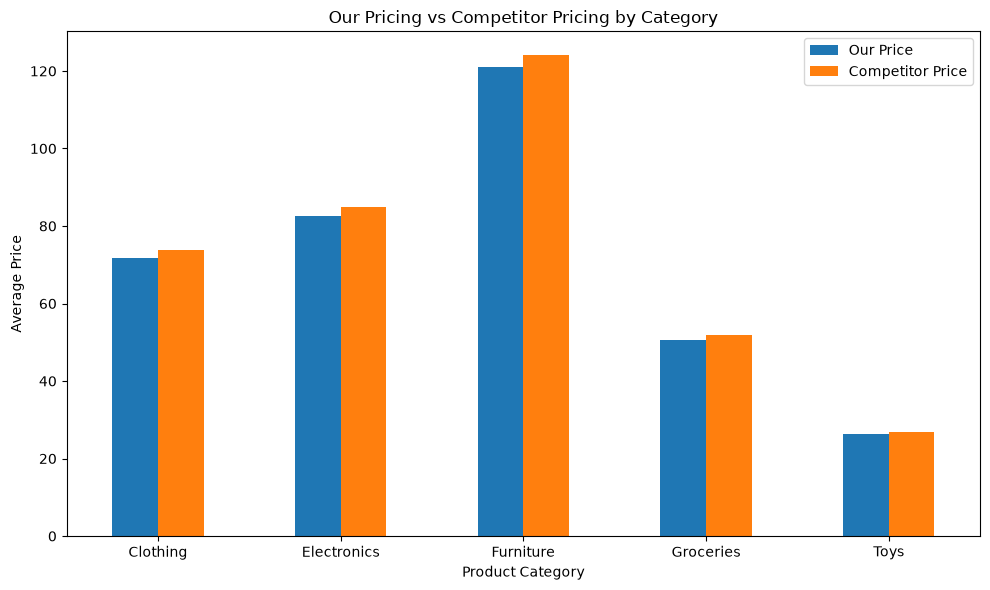

In [7]:
category_pricing[
    ["Average_Price", "Average_Competitor_Price"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Our Pricing vs Competitor Pricing by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.legend(["Our Price", "Competitor Price"])
plt.tight_layout()
plt.show()

In [8]:
discount_analysis = pricing_df.groupby(
    ["Category", "Discount"]
).agg(
    Average_Predicted_Demand=("Predicted_Demand", "mean"),
    Average_Price=("Price", "mean"),
    Records=("Discount", "count")
).reset_index()

display(
    discount_analysis.round(2)
)

,Category,Discount,Average_Predicted_Demand,Average_Price,Records
0,Clothing,0,107.62,76.70,533
1,Clothing,5,103.90,72.22,579
2,Clothing,10,112.12,71.32,744
3,Clothing,15,134.59,72.52,191
4,Clothing,20,128.91,65.32,178
5,Clothing,25,126.05,65.10,207
6,Electronics,0,93.30,89.98,419
7,Electronics,5,86.11,81.87,390
8,Electronics,10,93.77,82.13,571
9,Electronics,15,119.93,83.07,148


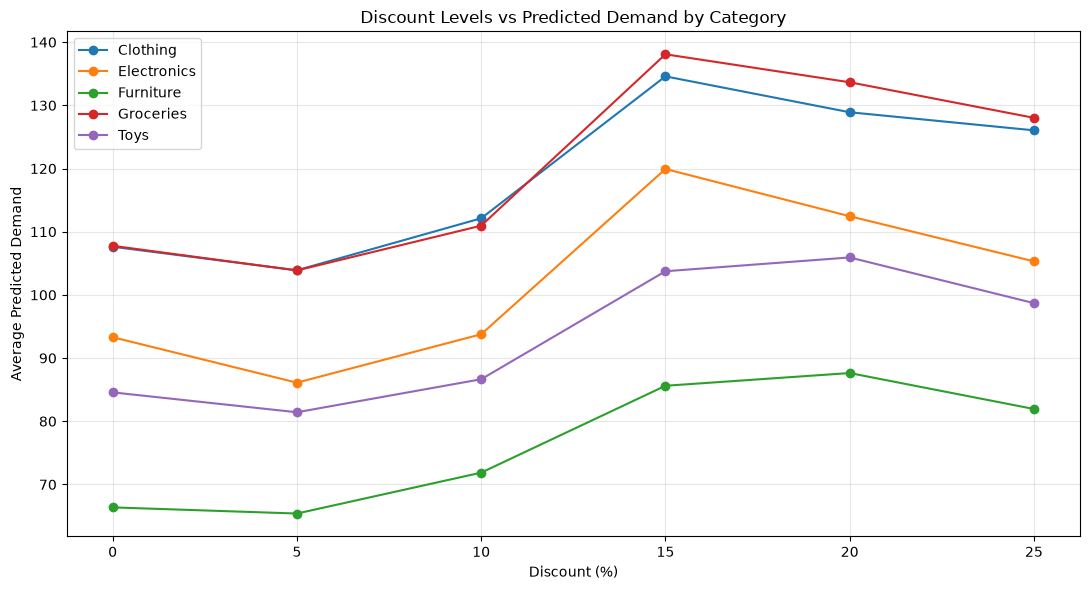

In [9]:
plt.figure(figsize=(11, 6))

for category in discount_analysis["Category"].unique():
    category_data = discount_analysis[
        discount_analysis["Category"] == category
    ]

    plt.plot(
        category_data["Discount"],
        category_data["Average_Predicted_Demand"],
        marker="o",
        label=category
    )

plt.title("Discount Levels vs Predicted Demand by Category")
plt.xlabel("Discount (%)")
plt.ylabel("Average Predicted Demand")
plt.xticks([0, 5, 10, 15, 20, 25])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
pricing_df["Estimated_Selling_Price"] = (
    pricing_df["Price"] *
    (1 - pricing_df["Discount"] / 100)
)

display(
    pricing_df[
        [
            "Category",
            "Price",
            "Discount",
            "Estimated_Selling_Price"
        ]
    ].head(10).round(2)
)

,Category,Price,Discount,Estimated_Selling_Price
60800,Groceries,36.89,25,27.67
60801,Groceries,27.56,10,24.80
60802,Furniture,125.19,0,125.19
60803,Groceries,19.67,10,17.70
60804,Groceries,25.97,15,22.07
60805,Clothing,62.63,10,56.37
60806,Electronics,107.36,5,101.99
60807,Clothing,71.71,5,68.12
60808,Clothing,88.64,25,66.48
60809,Groceries,67.65,5,64.27


In [11]:
pricing_df["Estimated_Sales_Value"] = (
    pricing_df["Estimated_Selling_Price"]
    * pricing_df["Units Sold"]
)

display(
    pricing_df[
        [
            "Category",
            "Estimated_Selling_Price",
            "Units Sold",
            "Estimated_Sales_Value"
        ]
    ].head(10).round(2)
)

,Category,Estimated_Selling_Price,Units Sold,Estimated_Sales_Value
60800,Groceries,27.67,166,4592.80
60801,Groceries,24.80,121,3001.28
60802,Furniture,125.19,99,12393.81
60803,Groceries,17.70,83,1469.35
60804,Groceries,22.07,157,3465.70
60805,Clothing,56.37,94,5298.50
60806,Electronics,101.99,54,5507.57
60807,Clothing,68.12,107,7289.32
60808,Clothing,66.48,77,5118.96
60809,Groceries,64.27,186,11953.76


In [12]:
assumed_cost_percentages = {
    "Clothing": 0.60,
    "Electronics": 0.70,
    "Furniture": 0.55,
    "Groceries": 0.75,
    "Toys": 0.65
}

pricing_df["Assumed_Cost_Percentage"] = (
    pricing_df["Category"].map(assumed_cost_percentages)
)

pricing_df["Estimated_Unit_Cost"] = (
    pricing_df["Price"] *
    pricing_df["Assumed_Cost_Percentage"]
)

display(
    pricing_df[
        [
            "Category",
            "Price",
            "Assumed_Cost_Percentage",
            "Estimated_Unit_Cost"
        ]
    ].head(10).round(2)
)

,Category,Price,Assumed_Cost_Percentage,Estimated_Unit_Cost
60800,Groceries,36.89,0.75,27.67
60801,Groceries,27.56,0.75,20.67
60802,Furniture,125.19,0.55,68.85
60803,Groceries,19.67,0.75,14.75
60804,Groceries,25.97,0.75,19.48
60805,Clothing,62.63,0.60,37.58
60806,Electronics,107.36,0.70,75.15
60807,Clothing,71.71,0.60,43.03
60808,Clothing,88.64,0.60,53.18
60809,Groceries,67.65,0.75,50.74


In [13]:
pricing_df["Estimated_Profit_Per_Unit"] = (
    pricing_df["Estimated_Selling_Price"]
    - pricing_df["Estimated_Unit_Cost"]
)

pricing_df["Estimated_Profit_Margin_%"] = (
    pricing_df["Estimated_Profit_Per_Unit"]
    / pricing_df["Estimated_Selling_Price"]
) * 100

display(
    pricing_df[
        [
            "Category",
            "Estimated_Selling_Price",
            "Estimated_Unit_Cost",
            "Estimated_Profit_Per_Unit",
            "Estimated_Profit_Margin_%"
        ]
    ].head(10).round(2)
)

,Category,Estimated_Selling_Price,Estimated_Unit_Cost,Estimated_Profit_Per_Unit,Estimated_Profit_Margin_%
60800,Groceries,27.67,27.67,0.00,0.00
60801,Groceries,24.80,20.67,4.13,16.67
60802,Furniture,125.19,68.85,56.34,45.00
60803,Groceries,17.70,14.75,2.95,16.67
60804,Groceries,22.07,19.48,2.60,11.76
60805,Clothing,56.37,37.58,18.79,33.33
60806,Electronics,101.99,75.15,26.84,26.32
60807,Clothing,68.12,43.03,25.10,36.84
60808,Clothing,66.48,53.18,13.30,20.00
60809,Groceries,64.27,50.74,13.53,21.05


In [14]:
pricing_df["Estimated_Total_Profit"] = (
    pricing_df["Estimated_Profit_Per_Unit"]
    * pricing_df["Units Sold"]
)

display(
    pricing_df[
        [
            "Category",
            "Units Sold",
            "Estimated_Profit_Per_Unit",
            "Estimated_Total_Profit"
        ]
    ].head(10).round(2)
)

,Category,Units Sold,Estimated_Profit_Per_Unit,Estimated_Total_Profit
60800,Groceries,166,0.00,0.00
60801,Groceries,121,4.13,500.21
60802,Furniture,99,56.34,5577.21
60803,Groceries,83,2.95,244.89
60804,Groceries,157,2.60,407.73
60805,Clothing,94,18.79,1766.17
60806,Electronics,54,26.84,1449.36
60807,Clothing,107,25.10,2685.54
60808,Clothing,77,13.30,1023.79
60809,Groceries,186,13.53,2516.58


In [15]:
category_profitability = pricing_df.groupby("Category").agg(
    Total_Units_Sold=("Units Sold", "sum"),
    Total_Estimated_Sales=("Estimated_Sales_Value", "sum"),
    Total_Estimated_Profit=("Estimated_Total_Profit", "sum"),
    Average_Profit_Per_Unit=("Estimated_Profit_Per_Unit", "mean"),
    Average_Profit_Margin=("Estimated_Profit_Margin_%", "mean")
)

display(
    category_profitability.sort_values(
        "Total_Estimated_Profit",
        ascending=False
    ).round(2)
)

,Total_Units_Sold,Total_Estimated_Sales,Total_Estimated_Profit,Average_Profit_Per_Unit,Average_Profit_Margin
Category,,,,,
Furniture,174302,19861809.80,7810869.90,43.98,39.10
Clothing,233670,15808236.35,5352225.77,22.50,33.58
Groceries,590184,28190121.84,4874821.01,8.26,16.89
Electronics,150693,11807907.68,2705997.50,17.67,22.52
Toys,157013,3974805.98,1124901.56,6.92,27.89


In [16]:
category_profitability["Overall_Profit_Margin_%"] = (
    category_profitability["Total_Estimated_Profit"]
    / category_profitability["Total_Estimated_Sales"]
) * 100

display(
    category_profitability[
        [
            "Total_Estimated_Sales",
            "Total_Estimated_Profit",
            "Overall_Profit_Margin_%"
        ]
    ].round(2)
)

,Total_Estimated_Sales,Total_Estimated_Profit,Overall_Profit_Margin_%
Category,,,
Clothing,15808236.35,5352225.77,33.86
Electronics,11807907.68,2705997.50,22.92
Furniture,19861809.80,7810869.90,39.33
Groceries,28190121.84,4874821.01,17.29
Toys,3974805.98,1124901.56,28.30


In [17]:
total_sales = pricing_df["Estimated_Sales_Value"].sum()

total_profit = pricing_df["Estimated_Total_Profit"].sum()

overall_margin = (total_profit / total_sales) * 100

print("Total Estimated Sales:", round(total_sales, 2))
print("Total Estimated Profit:", round(total_profit, 2))
print("Overall Estimated Profit Margin:", round(overall_margin, 2), "%")

Total Estimated Sales: 79642881.67
Total Estimated Profit: 21868815.74
Overall Estimated Profit Margin: 27.46 %


In [18]:
category_profitability["Profit_Contribution_%"] = (
    category_profitability["Total_Estimated_Profit"]
    / total_profit
) * 100

display(
    category_profitability[
        [
            "Total_Estimated_Profit",
            "Profit_Contribution_%"
        ]
    ].sort_values(
        "Profit_Contribution_%",
        ascending=False
    ).round(2)
)

,Total_Estimated_Profit,Profit_Contribution_%
Category,,
Furniture,7810869.90,35.72
Clothing,5352225.77,24.47
Groceries,4874821.01,22.29
Electronics,2705997.50,12.37
Toys,1124901.56,5.14


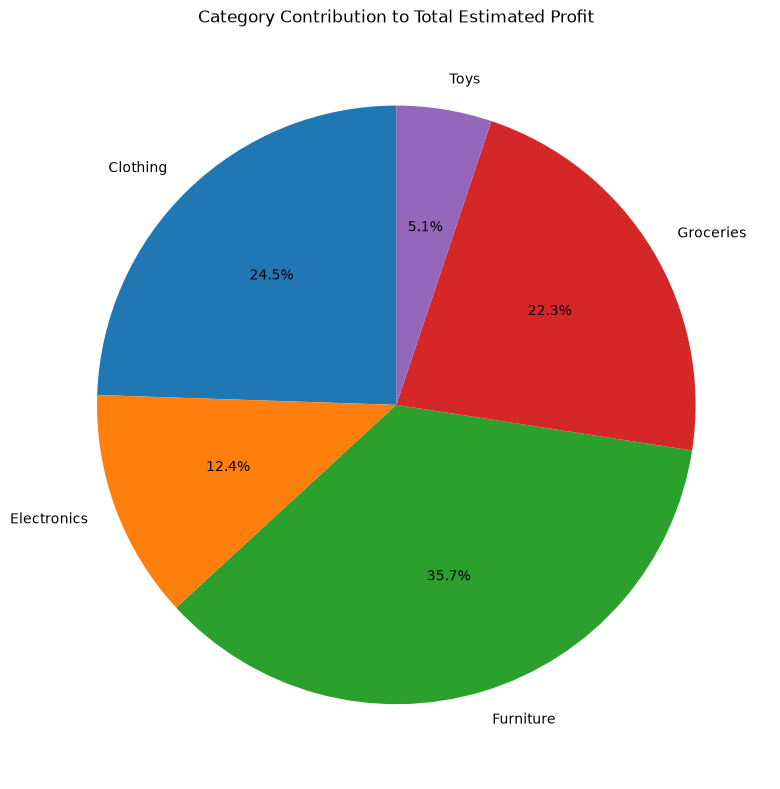

In [19]:
category_profitability["Profit_Contribution_%"].plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category Contribution to Total Estimated Profit")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [20]:
discount_profitability = pricing_df.groupby(
    ["Category", "Discount"]
).agg(
    Total_Sales=("Estimated_Sales_Value", "sum"),
    Total_Profit=("Estimated_Total_Profit", "sum"),
    Total_Units=("Units Sold", "sum")
).reset_index()

discount_profitability["Profit_Margin_%"] = (
    discount_profitability["Total_Profit"]
    / discount_profitability["Total_Sales"]
) * 100

display(discount_profitability.round(2))

,Category,Discount,Total_Sales,Total_Profit,Total_Units,Profit_Margin_%
0,Clothing,0,3801847.15,1520738.86,47649,40.00
1,Clothing,5,3656204.32,1347022.65,51114,36.84
2,Clothing,10,4754908.50,1584969.50,71512,33.33
3,Clothing,15,1339550.69,393985.50,20738,29.41
4,Clothing,20,1087282.66,271820.67,19640,25.00
5,Clothing,25,1168443.02,233688.60,23017,20.00
6,Electronics,0,3095844.83,928753.45,32650,30.00
7,Electronics,5,2378610.42,625950.11,29112,26.32
8,Electronics,10,3567324.62,792738.80,46572,22.22
9,Electronics,15,1064574.32,187866.06,14275,17.65


In [11]:
import matplotlib.pyplot as plt

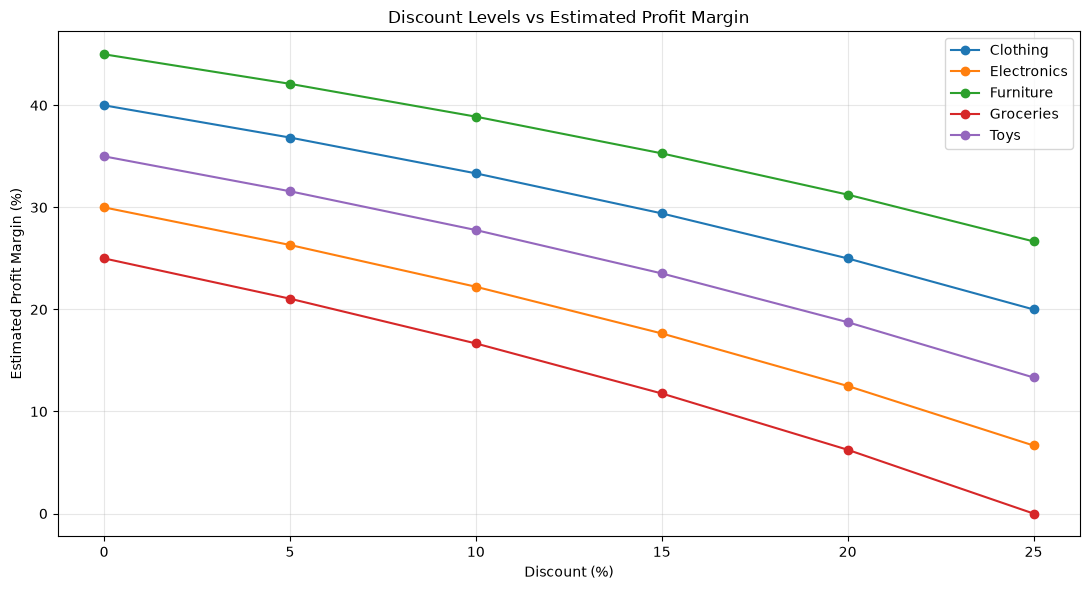

In [12]:
plt.figure(figsize=(11, 6))

for category in discount_profitability["Category"].unique():
    category_data = discount_profitability[
        discount_profitability["Category"] == category
    ]

    plt.plot(
        category_data["Discount"],
        category_data["Profit_Margin_%"],
        marker="o",
        label=category
    )

plt.title("Discount Levels vs Estimated Profit Margin")
plt.xlabel("Discount (%)")
plt.ylabel("Estimated Profit Margin (%)")
plt.xticks([0, 5, 10, 15, 20, 25])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
discount_profitability = pricing_df.groupby(
    ["Category", "Discount"]
).agg(
    Total_Sales=("Estimated_Sales_Value", "sum"),
    Total_Profit=("Estimated_Total_Profit", "sum"),
    Total_Units=("Units Sold", "sum")
).reset_index()

discount_profitability["Profit_Margin_%"] = (
    discount_profitability["Total_Profit"] /
    discount_profitability["Total_Sales"]
) * 100

discount_profitability.head()

,Category,Discount,Total_Sales,Total_Profit,Total_Units,Profit_Margin_%
0,Clothing,0,3.801847e+06,1.520739e+06,47649,40.000000
1,Clothing,5,3.656204e+06,1.347023e+06,51114,36.842105
2,Clothing,10,4.754909e+06,1.584970e+06,71512,33.333333
3,Clothing,15,1.339551e+06,3.939855e+05,20738,29.411765
4,Clothing,20,1.087283e+06,2.718207e+05,19640,25.000000


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Data/Raw/retail_demand.csv")
predictions = pd.read_csv("../Reports/final_demand_predictions.csv")

print("Dataset:", df.shape)
print("Predictions:", predictions.shape)

Dataset: (76000, 16)
Predictions: (15200, 4)


In [15]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

split_date = df["Date"].unique()[
    int(len(df["Date"].unique()) * 0.80)
]

test_df = df[df["Date"] >= split_date].copy()

print("Test dataset:", test_df.shape)
print("Dates match:", test_df["Date"].reset_index(drop=True).equals(
    pd.to_datetime(predictions["Date"]).reset_index(drop=True)
))

Test dataset: (15200, 16)
Dates match: True


In [16]:
pricing_df = test_df.copy()

pricing_df["Predicted_Demand"] = predictions[
    "Predicted_Demand"
].values

print("Pricing dataset:", pricing_df.shape)
print(pricing_df[["Date", "Demand", "Predicted_Demand"]].head())

Pricing dataset: (15200, 17)
            Date  Demand  Predicted_Demand
60800 2023-09-01     182            169.03
60801 2023-09-01     102            123.85
60802 2023-09-01     150            119.26
60803 2023-09-01     117            139.77
60804 2023-09-01     134            150.61


In [17]:
pricing_df["Estimated_Selling_Price"] = (
    pricing_df["Price"] * (1 - pricing_df["Discount"] / 100)
)

pricing_df["Estimated_Sales_Value"] = (
    pricing_df["Estimated_Selling_Price"] * pricing_df["Units Sold"]
)

pricing_df[[
    "Category", "Price", "Discount",
    "Estimated_Selling_Price", "Units Sold",
    "Estimated_Sales_Value"
]].head()

,Category,Price,Discount,Estimated_Selling_Price,Units Sold,Estimated_Sales_Value
60800,Groceries,36.89,25,27.6675,166,4592.8050
60801,Groceries,27.56,10,24.8040,121,3001.2840
60802,Furniture,125.19,0,125.1900,99,12393.8100
60803,Groceries,19.67,10,17.7030,83,1469.3490
60804,Groceries,25.97,15,22.0745,157,3465.6965


In [18]:
assumed_cost_percentages = {
    "Clothing": 0.60,
    "Electronics": 0.70,
    "Furniture": 0.55,
    "Groceries": 0.75,
    "Toys": 0.65
}

pricing_df["Assumed_Cost_Percentage"] = (
    pricing_df["Category"].map(assumed_cost_percentages)
)

pricing_df["Estimated_Unit_Cost"] = (
    pricing_df["Price"] * pricing_df["Assumed_Cost_Percentage"]
)

pricing_df[[
    "Category", "Price",
    "Assumed_Cost_Percentage", "Estimated_Unit_Cost"
]].head()

,Category,Price,Assumed_Cost_Percentage,Estimated_Unit_Cost
60800,Groceries,36.89,0.75,27.6675
60801,Groceries,27.56,0.75,20.6700
60802,Furniture,125.19,0.55,68.8545
60803,Groceries,19.67,0.75,14.7525
60804,Groceries,25.97,0.75,19.4775


In [19]:
pricing_df["Estimated_Profit_Per_Unit"] = (
    pricing_df["Estimated_Selling_Price"]
    - pricing_df["Estimated_Unit_Cost"]
)

pricing_df["Estimated_Profit_Margin_%"] = (
    pricing_df["Estimated_Profit_Per_Unit"]
    / pricing_df["Estimated_Selling_Price"]
) * 100

pricing_df["Estimated_Total_Profit"] = (
    pricing_df["Estimated_Profit_Per_Unit"]
    * pricing_df["Units Sold"]
)

pricing_df[[
    "Category",
    "Estimated_Selling_Price",
    "Estimated_Unit_Cost",
    "Estimated_Profit_Per_Unit",
    "Estimated_Profit_Margin_%"
]].head()

,Category,Estimated_Selling_Price,Estimated_Unit_Cost,Estimated_Profit_Per_Unit,Estimated_Profit_Margin_%
60800,Groceries,27.6675,27.6675,0.0000,0.000000
60801,Groceries,24.8040,20.6700,4.1340,16.666667
60802,Furniture,125.1900,68.8545,56.3355,45.000000
60803,Groceries,17.7030,14.7525,2.9505,16.666667
60804,Groceries,22.0745,19.4775,2.5970,11.764706


In [20]:
discount_profitability = pricing_df.groupby(
    ["Category", "Discount"]
).agg(
    Total_Sales=("Estimated_Sales_Value", "sum"),
    Total_Profit=("Estimated_Total_Profit", "sum"),
    Total_Units=("Units Sold", "sum")
).reset_index()

discount_profitability["Profit_Margin_%"] = (
    discount_profitability["Total_Profit"]
    / discount_profitability["Total_Sales"]
) * 100

discount_profitability.head(10)

,Category,Discount,Total_Sales,Total_Profit,Total_Units,Profit_Margin_%
0,Clothing,0,3.801847e+06,1.520739e+06,47649,40.000000
1,Clothing,5,3.656204e+06,1.347023e+06,51114,36.842105
2,Clothing,10,4.754909e+06,1.584970e+06,71512,33.333333
3,Clothing,15,1.339551e+06,3.939855e+05,20738,29.411765
4,Clothing,20,1.087283e+06,2.718207e+05,19640,25.000000
5,Clothing,25,1.168443e+06,2.336886e+05,23017,20.000000
6,Electronics,0,3.095845e+06,9.287534e+05,32650,30.000000
7,Electronics,5,2.378610e+06,6.259501e+05,29112,26.315789
8,Electronics,10,3.567325e+06,7.927388e+05,46572,22.222222
9,Electronics,15,1.064574e+06,1.878661e+05,14275,17.647059


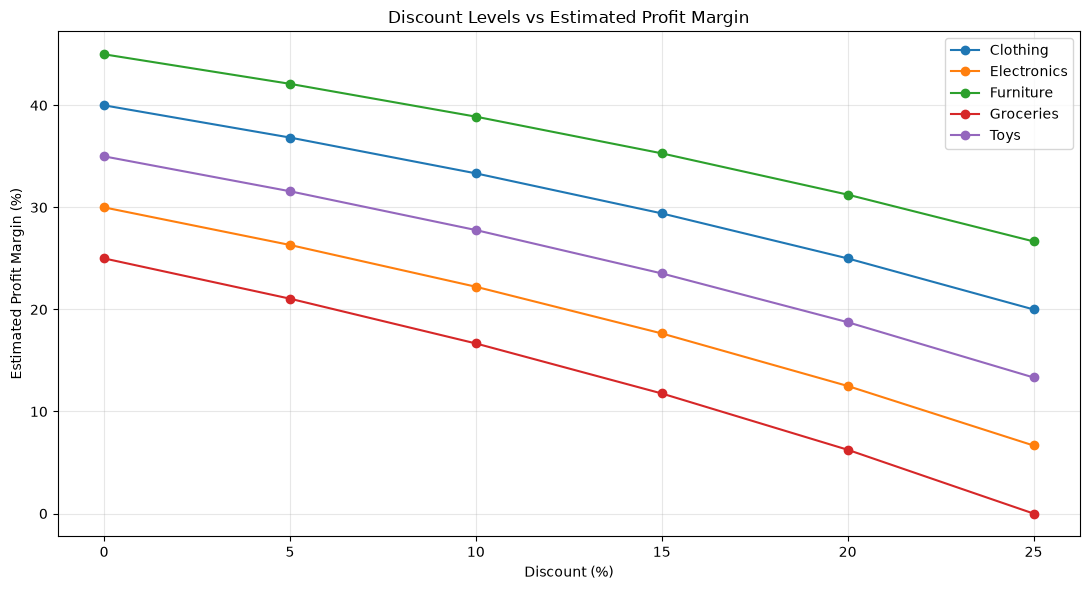

In [21]:
plt.figure(figsize=(11, 6))

for category in discount_profitability["Category"].unique():
    category_data = discount_profitability[
        discount_profitability["Category"] == category
    ]

    plt.plot(
        category_data["Discount"],
        category_data["Profit_Margin_%"],
        marker="o",
        label=category
    )

plt.title("Discount Levels vs Estimated Profit Margin")
plt.xlabel("Discount (%)")
plt.ylabel("Estimated Profit Margin (%)")
plt.xticks([0, 5, 10, 15, 20, 25])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

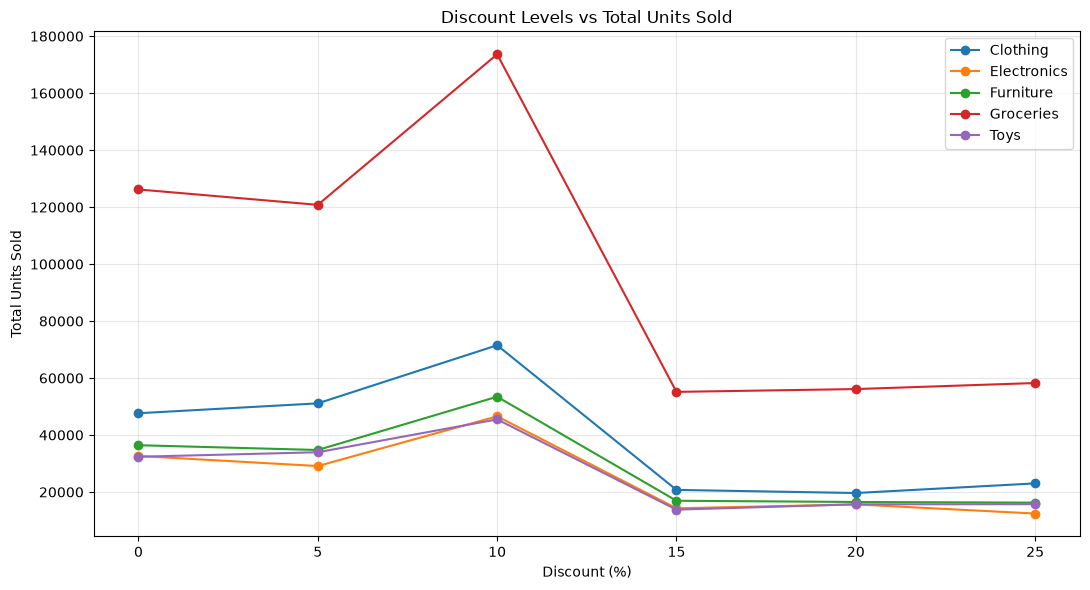

In [22]:
plt.figure(figsize=(11, 6))

for category in discount_profitability["Category"].unique():
    category_data = discount_profitability[
        discount_profitability["Category"] == category
    ]

    plt.plot(
        category_data["Discount"],
        category_data["Total_Units"],
        marker="o",
        label=category
    )

plt.title("Discount Levels vs Total Units Sold")
plt.xlabel("Discount (%)")
plt.ylabel("Total Units Sold")
plt.xticks([0, 5, 10, 15, 20, 25])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
discount_summary = discount_profitability.pivot_table(
    index="Discount",
    columns="Category",
    values="Total_Profit",
    aggfunc="sum"
)

discount_summary.round(2)

Category,Clothing,Electronics,Furniture,Groceries,Toys
Discount,,,,,
0,1520738.86,928753.45,2190732.08,1794484.36,341750.44
5,1347022.65,625950.11,1779462.08,1315246.73,290879.65
10,1584969.50,792738.80,2368424.68,1338118.18,315216.28
15,393985.50,187866.06,623490.54,285837.29,77711.59
20,271820.67,122683.24,495180.95,141134.45,61325.81
25,233688.60,48005.84,353579.57,0.00,38017.78


In [24]:
best_discount_by_category = discount_profitability.loc[
    discount_profitability.groupby("Category")["Total_Profit"].idxmax(),
    ["Category", "Discount", "Total_Profit"]
].sort_values("Total_Profit", ascending=False)

best_discount_by_category.round(2)

,Category,Discount,Total_Profit
14,Furniture,10,2368424.68
18,Groceries,0,1794484.36
2,Clothing,10,1584969.50
6,Electronics,0,928753.45
24,Toys,0,341750.44


In [25]:
best_discount_details = discount_profitability.loc[
    discount_profitability.groupby("Category")["Total_Profit"].idxmax(),
    ["Category", "Discount", "Total_Sales",
     "Total_Profit", "Total_Units", "Profit_Margin_%"]
].sort_values("Total_Profit", ascending=False)

best_discount_details.round(2)

,Category,Discount,Total_Sales,Total_Profit,Total_Units,Profit_Margin_%
14,Furniture,10,6090234.89,2368424.68,53448,38.89
18,Groceries,0,7177937.46,1794484.36,126201,25.00
2,Clothing,10,4754908.50,1584969.50,71512,33.33
6,Electronics,0,3095844.83,928753.45,32650,30.00
24,Toys,0,976429.82,341750.44,32367,35.00


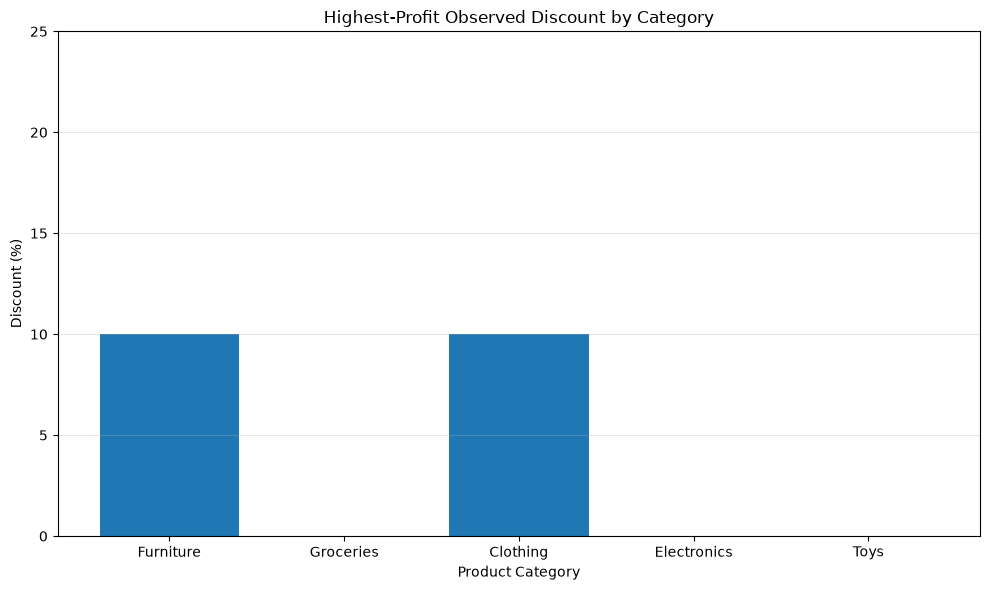

In [26]:
plt.figure(figsize=(10, 6))

plt.bar(
    best_discount_details["Category"],
    best_discount_details["Discount"]
)

plt.title("Highest-Profit Observed Discount by Category")
plt.xlabel("Product Category")
plt.ylabel("Discount (%)")
plt.yticks([0, 5, 10, 15, 20, 25])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
discount_profitability["Profit_Per_Unit_Sold"] = (
    discount_profitability["Total_Profit"]
    / discount_profitability["Total_Units"]
)

profit_per_unit_summary = discount_profitability.pivot_table(
    index="Discount",
    columns="Category",
    values="Profit_Per_Unit_Sold"
)

profit_per_unit_summary.round(2)

Category,Clothing,Electronics,Furniture,Groceries,Toys
Discount,,,,,
0,31.92,28.45,60.15,14.22,10.56
5,26.35,21.50,51.21,10.89,8.57
10,22.16,17.02,44.31,7.71,6.93
15,19.00,13.16,36.84,5.18,5.63
20,13.84,7.84,30.01,2.51,3.91
25,10.15,3.86,21.74,0.00,2.42


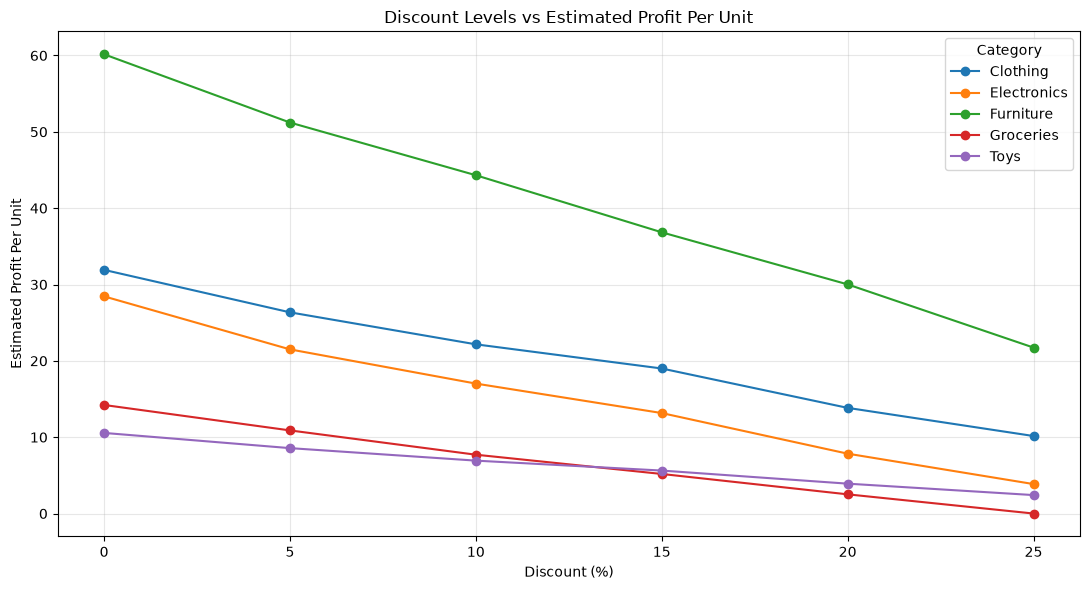

In [28]:
profit_per_unit_summary.plot(
    kind="line",
    marker="o",
    figsize=(11, 6)
)

plt.title("Discount Levels vs Estimated Profit Per Unit")
plt.xlabel("Discount (%)")
plt.ylabel("Estimated Profit Per Unit")
plt.xticks([0, 5, 10, 15, 20, 25])
plt.grid(alpha=0.3)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

In [29]:
break_even_discount = pd.DataFrame({
    "Category": list(assumed_cost_percentages.keys()),
    "Assumed_Cost_Percentage": list(assumed_cost_percentages.values())
})

break_even_discount["Break_Even_Discount_%"] = (
    1 - break_even_discount["Assumed_Cost_Percentage"]
) * 100

break_even_discount

,Category,Assumed_Cost_Percentage,Break_Even_Discount_%
0,Clothing,0.60,40.0
1,Electronics,0.70,30.0
2,Furniture,0.55,45.0
3,Groceries,0.75,25.0
4,Toys,0.65,35.0


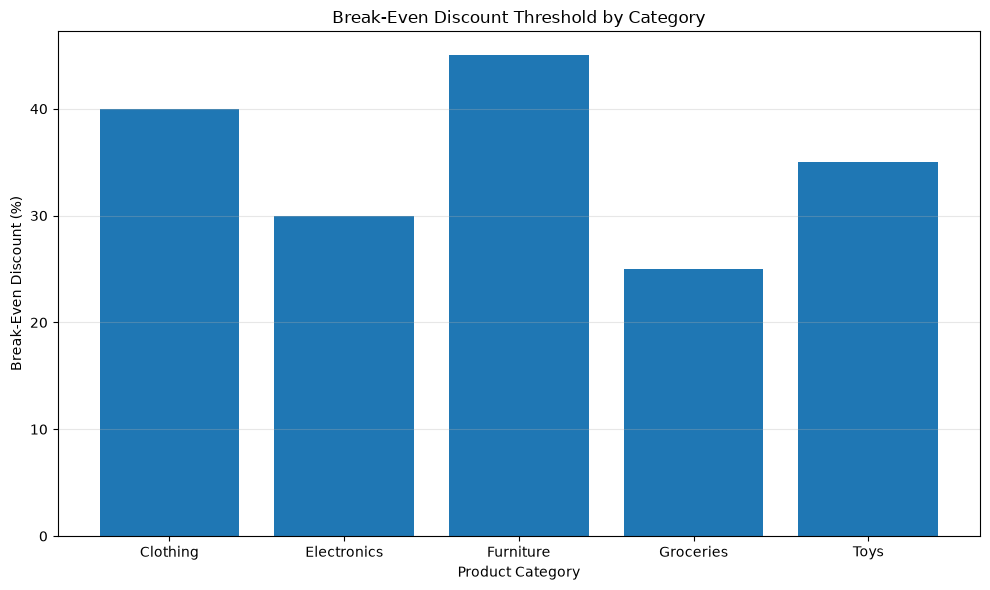

In [30]:
plt.figure(figsize=(10, 6))

plt.bar(
    break_even_discount["Category"],
    break_even_discount["Break_Even_Discount_%"]
)

plt.title("Break-Even Discount Threshold by Category")
plt.xlabel("Product Category")
plt.ylabel("Break-Even Discount (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
pricing_decision_summary = best_discount_details.merge(
    break_even_discount[
        ["Category", "Break_Even_Discount_%"]
    ],
    on="Category",
    how="left"
)

pricing_decision_summary["Discount_Headroom_%"] = (
    pricing_decision_summary["Break_Even_Discount_%"]
    - pricing_decision_summary["Discount"]
)

pricing_decision_summary = pricing_decision_summary.sort_values(
    "Total_Profit", ascending=False
)

pricing_decision_summary.round(2)

,Category,Discount,Total_Sales,Total_Profit,Total_Units,Profit_Margin_%,Break_Even_Discount_%,Discount_Headroom_%
0,Furniture,10,6090234.89,2368424.68,53448,38.89,45.0,35.0
1,Groceries,0,7177937.46,1794484.36,126201,25.00,25.0,25.0
2,Clothing,10,4754908.50,1584969.50,71512,33.33,40.0,30.0
3,Electronics,0,3095844.83,928753.45,32650,30.00,30.0,30.0
4,Toys,0,976429.82,341750.44,32367,35.00,35.0,35.0


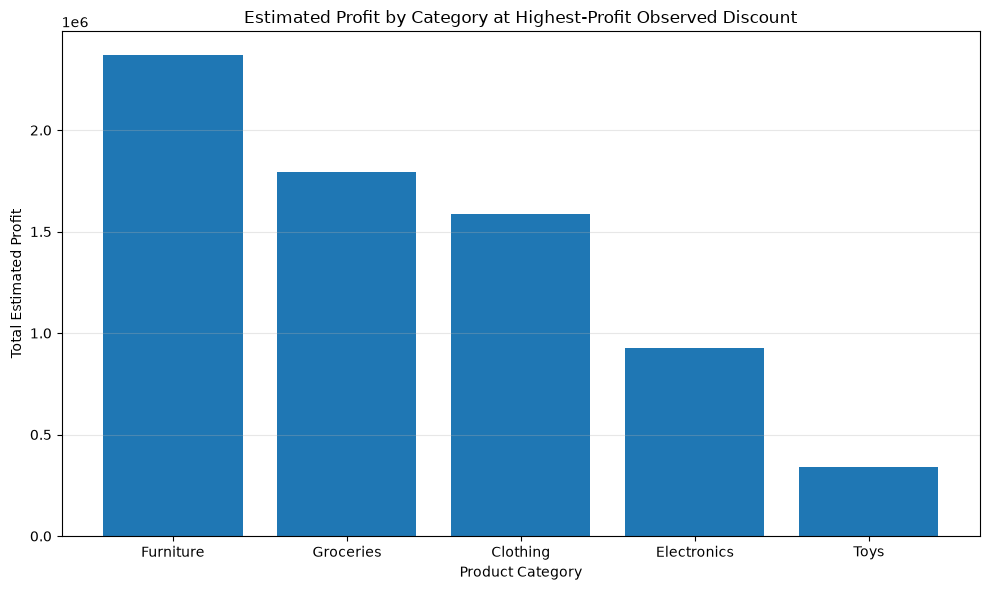

In [32]:
plt.figure(figsize=(10, 6))

plt.bar(
    pricing_decision_summary["Category"],
    pricing_decision_summary["Total_Profit"]
)

plt.title("Estimated Profit by Category at Highest-Profit Observed Discount")
plt.xlabel("Product Category")
plt.ylabel("Total Estimated Profit")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
pricing_decision_summary["Profit_Contribution_%"] = (
    pricing_decision_summary["Total_Profit"]
    / pricing_decision_summary["Total_Profit"].sum()
) * 100

pricing_decision_summary[
    ["Category", "Total_Profit", "Profit_Contribution_%"]
].round(2)

,Category,Total_Profit,Profit_Contribution_%
0,Furniture,2368424.68,33.75
1,Groceries,1794484.36,25.57
2,Clothing,1584969.50,22.58
3,Electronics,928753.45,13.23
4,Toys,341750.44,4.87


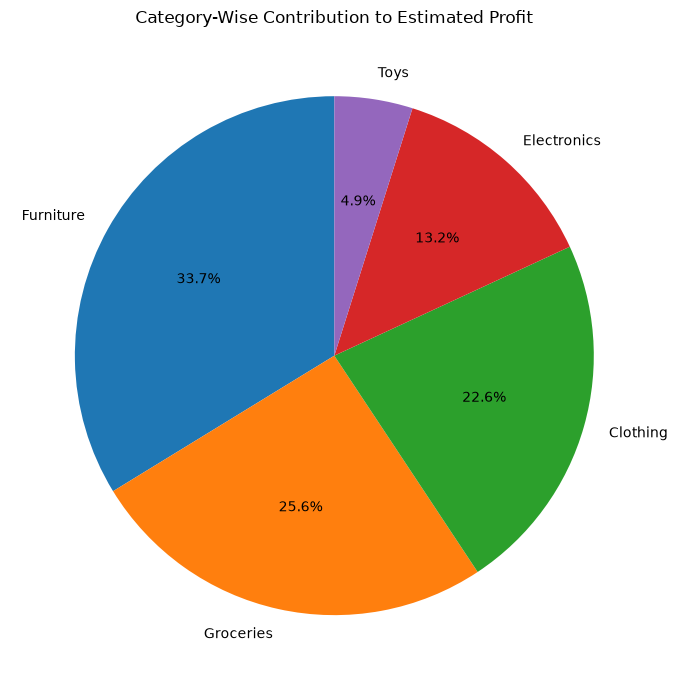

In [34]:
plt.figure(figsize=(9, 7))

plt.pie(
    pricing_decision_summary["Profit_Contribution_%"],
    labels=pricing_decision_summary["Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category-Wise Contribution to Estimated Profit")
plt.tight_layout()
plt.show()

## Key Findings — Pricing & Profitability Optimization

### 1. Category Profitability
- Furniture generated the highest estimated profit in the overall analysis.
- Groceries generated the highest estimated sales value but had a comparatively lower estimated profit margin.
- Furniture and Clothing were major contributors to estimated profitability.

### 2. Discount Analysis
- Estimated profit margins declined as discount levels increased.
- Clothing and Furniture recorded their highest observed total estimated profit at a 10% discount.
- Groceries, Electronics, and Toys recorded their highest observed total estimated profit at a 0% discount.

### 3. Unit Economics
- Estimated profit per unit declined across all categories as discounts increased.
- Groceries reached zero estimated unit profit at a 25% discount under the assumed cost structure.
- Furniture had the highest theoretical break-even discount at 45%.

### 4. Category Contribution
In the selected highest-profit observed discount groups:
- Furniture contributed 33.75% of estimated profit.
- Groceries contributed 25.57%.
- Clothing contributed 22.58%.
- Electronics contributed 13.23%.
- Toys contributed 4.87%.

### 5. Business Interpretation
The analysis demonstrates that pricing decisions should consider sales volume, estimated profit per unit, profit margin, and category-level contribution together rather than focusing only on demand or sales value.

### Important Limitations
- Product costs are hypothetical assumptions, not verified business costs.
- The meaning of the recorded Price field requires confirmation.
- Currency and additional operating expenses are not available.
- Historical discount groups have different sales volumes and are not controlled experiments.
- The analysis does not establish causal relationships or identify proven optimal prices.
- Demand predictions are estimates from a historical test period and do not measure how demand would respond to hypothetical price changes.

Therefore, all profitability results should be interpreted as illustrative scenario estimates rather than actual business financial outcomes.

In [35]:
print("Pricing Dataset:", pricing_df.shape)

print("\nMissing Values:")
print(pricing_df[[
    "Estimated_Selling_Price",
    "Estimated_Sales_Value",
    "Estimated_Unit_Cost",
    "Estimated_Profit_Per_Unit",
    "Estimated_Total_Profit"
]].isnull().sum())

print("\nFinal Profitability Summary:")
print(
    pricing_df[
        ["Estimated_Sales_Value", "Estimated_Total_Profit"]
    ].sum().round(2)
)

Pricing Dataset: (15200, 24)

Missing Values:
Estimated_Selling_Price      0
Estimated_Sales_Value        0
Estimated_Unit_Cost          0
Estimated_Profit_Per_Unit    0
Estimated_Total_Profit       0
dtype: int64

Final Profitability Summary:
Estimated_Sales_Value     79642881.67
Estimated_Total_Profit    21868815.74
dtype: float64
